# Семинар 5. Нелинейная задача ОУ: маятник

На прошлой паре мы научились считать градиент функционала по управлению через сопряжённую систему. Сегодня ничего нового в ПМП выводить не будем: возьмём этот градиент и посмотрим, как из него получается рабочий алгоритм оптимизации.

Будем решать задачу для маятника
$$
\dot\theta=\omega,\qquad
\dot\omega=-\sin\theta+u,
$$
с начальным состоянием
$$
(\theta(0),\omega(0))=(0,0)
$$
и целью
$$
(\theta(T),\omega(T))\approx(\pi,0).
$$

Управление ограничено:
$$
|u(t)|\le 2.
$$

Функционал:
$$
J=
20(\theta(T)-\pi)^2+
5\omega(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

Сегодня сравним три подхода:

- обычный projected gradient с фиксированным шагом;
- projected gradient с подбором шага;
- `L-BFGS-B`, которому мы сами передадим градиент.

## 0. Импорт

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from scipy.optimize import minimize
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

## 1. Маятник и градиент

Используем ту же дискретизацию, что была в домашней работе:
$$
\theta_{k+1}=\theta_k+h\omega_k,
$$
$$
\omega_{k+1}
=
\omega_k+h(-\sin\theta_k+u_k).
$$

Возьмём $T=5$ и $N=80$. При такой сетке нелинейность уже хорошо проявляется, а расчёты остаются быстрыми.

In [2]:
T = 5.0
N = 80
u_max = 2.0

x0 = np.array([0.0, 0.0])
x_target = np.array([np.pi, 0.0])

w_theta = 20.0
w_omega = 5.0
lam = 0.05


def simulate_pendulum(u):
    n = len(u)
    h = T / n

    x = np.zeros((n + 1, 2))
    x[0] = x0

    for k in range(n):
        theta, omega = x[k]

        x[k + 1, 0] = theta + h * omega
        x[k + 1, 1] = omega + h * (-np.sin(theta) + u[k])

    return x


def objective_pendulum(u, lam_value=lam):
    h = T / len(u)
    x = simulate_pendulum(u)

    e = x[-1] - x_target

    terminal_cost = (
        w_theta * e[0]**2
        + w_omega * e[1]**2
    )

    control_cost = (
        lam_value * h * np.sum(u**2)
    )

    return terminal_cost + control_cost

Ниже используется проверенная реализация сопряжённого градиента из прошлой работы.

Для Euler-схемы
$$
F_x=
\begin{pmatrix}
1 & h\\
-h\cos\theta_k & 1
\end{pmatrix},
\qquad
F_u=
\begin{pmatrix}
0\\
h
\end{pmatrix}.
$$

Поэтому
$$
p_k=F_x^\mathsf{T}p_{k+1},
$$
а компонент градиента по $u_k$ равен
$$
g_k
=
2\lambda h u_k+h\,p_{2,k+1}.
$$

In [3]:
def adjoint_gradient_pendulum(u, lam_value=lam):
    n = len(u)
    h = T / n

    x = simulate_pendulum(u)

    p = np.zeros_like(x)
    grad = np.zeros(n)

    e = x[-1] - x_target
    p[-1] = np.array([
        2 * w_theta * e[0],
        2 * w_omega * e[1],
    ])

    for k in range(n - 1, -1, -1):
        theta = x[k, 0]

        F_x = np.array([
            [1.0, h],
            [-h * np.cos(theta), 1.0],
        ])

        grad[k] = (
            2 * lam_value * h * u[k]
            + h * p[k + 1, 1]
        )

        p[k] = F_x.T @ p[k + 1]

    return grad

### Проверка градиента

Перед оптимизацией проверим градиент через производную по направлению.

Возьмём случайное направление $v$ и сравним
$$
\nabla J(u)^\mathsf{T}v
$$
с
$$
\frac{J(u+\varepsilon v)-J(u-\varepsilon v)}{2\varepsilon}.
$$

In [4]:
rng = np.random.default_rng(42)

u_test = 0.2 * rng.normal(size=N)
v = rng.normal(size=N)
v /= np.linalg.norm(v)

eps = 1e-6

g_test = adjoint_gradient_pendulum(u_test)

directional_adjoint = g_test @ v
directional_fd = (
    objective_pendulum(u_test + eps * v)
    - objective_pendulum(u_test - eps * v)
) / (2 * eps)

relative_error = (
    abs(directional_adjoint - directional_fd)
    / max(1.0, abs(directional_adjoint))
)

print("adjoint:", directional_adjoint)
print("finite difference:", directional_fd)
print("relative error:", relative_error)

adjoint: -4.5337930246154805
finite difference: -4.53379303166912
relative error: 1.5557921175511446e-09


Относительная ошибка порядка $10^{-7}$–$10^{-9}$ показывает хорошее согласование двух способов вычисления производной.

## 2. Projected gradient с фиксированным шагом

Для ограничений
$$
-2\le u_k\le2
$$
проекция — это обычный `np.clip`.

Один шаг:
$$
u^{m+1}
=
P_U\left(u^m-\alpha\nabla J(u^m)\right).
$$

Остаётся выбрать шаг $\alpha$.

Сначала сравним несколько фиксированных значений шага.

**Перед запуском:** что вы ожидаете от слишком маленького и слишком большого $\alpha$?

In [5]:
def projected_gradient_fixed(
    u0,
    alpha,
    maxiter=250,
    lam_value=lam,
):
    u = u0.copy()
    history = [objective_pendulum(u, lam_value)]

    for _ in range(maxiter):
        grad = adjoint_gradient_pendulum(u, lam_value)

        u = np.clip(
            u - alpha * grad,
            -u_max,
            u_max,
        )

        history.append(
            objective_pendulum(u, lam_value)
        )

    return u, np.array(history)

In [6]:
u0 = np.zeros(N)

fixed_results = {}

for alpha in [0.01, 0.03, 0.10]:
    u_fixed, history_fixed = projected_gradient_fixed(
        u0,
        alpha=alpha,
    )

    fixed_results[alpha] = {
        "u": u_fixed,
        "history": history_fixed,
    }

    print(
        f"alpha={alpha:0.2f}: "
        f"J={history_fixed[-1]:.6f}"
    )

alpha=0.01: J=1.151577
alpha=0.03: J=0.193732
alpha=0.10: J=5.087967


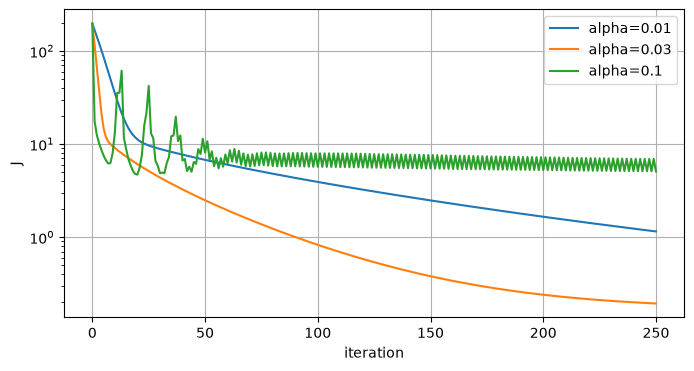

In [7]:
plt.figure(figsize=(8, 4))

for alpha, result in fixed_results.items():
    plt.semilogy(
        result["history"],
        label=f"alpha={alpha}",
    )

plt.xlabel("iteration")
plt.ylabel("J")
plt.grid()
plt.legend()
plt.show()

На этой задаче шаг $0.03$ работает неплохо, $0.01$ идёт медленно, а $0.10$ уже ведёт себя заметно хуже.

Подходящее значение шага зависит от задачи. Поэтому удобно выбирать его автоматически.

## 3. Backtracking line search

Сделаем простой line search.

На каждой итерации начинаем с некоторого $\alpha_0$. Если новый шаг недостаточно уменьшает функционал, уменьшаем
$$
\alpha\leftarrow\beta\alpha,
\qquad 0<\beta<1.
$$

Шаг принимается, если
$$
J(u_{\rm new})
\le
J(u)+c\,\nabla J(u)^\mathsf{T}
(u_{\rm new}-u).
$$

Это удобная форма условия Армихо для шага с проекцией.

Градиент задаёт направление, line search — длину шага.

In [8]:
def projected_gradient_backtracking(
    u0,
    alpha0=0.3,
    beta=0.5,
    c=1e-4,
    maxiter=250,
    tol=1e-8,
    lam_value=lam,
):
    u = u0.copy()

    history = [
        objective_pendulum(u, lam_value)
    ]
    accepted_alpha = []

    for _ in range(maxiter):
        J_current = history[-1]
        grad = adjoint_gradient_pendulum(
            u,
            lam_value,
        )

        alpha = alpha0

        while True:
            u_new = np.clip(
                u - alpha * grad,
                -u_max,
                u_max,
            )

            direction = u_new - u

            J_new = objective_pendulum(
                u_new,
                lam_value,
            )

            if J_new <= (
                J_current
                + c * grad @ direction
            ):
                break

            alpha *= beta

        accepted_alpha.append(alpha)
        history.append(J_new)

        if np.linalg.norm(
            direction,
            ord=np.inf,
        ) < tol:
            u = u_new
            break

        u = u_new

    return (
        u,
        np.array(history),
        np.array(accepted_alpha),
    )

In [9]:
u_bt, history_bt, alpha_bt = (
    projected_gradient_backtracking(u0)
)

x_bt = simulate_pendulum(u_bt)

print("J =", objective_pendulum(u_bt))
print("x(T) =", x_bt[-1])
print("iterations =", len(history_bt) - 1)
print("accepted alpha values =", np.unique(alpha_bt))

J = 0.1716351494853423
x(T) = [3.12955567 0.040446  ]
iterations = 250
accepted alpha values = [0.01875 0.0375  0.075   0.15    0.3    ]


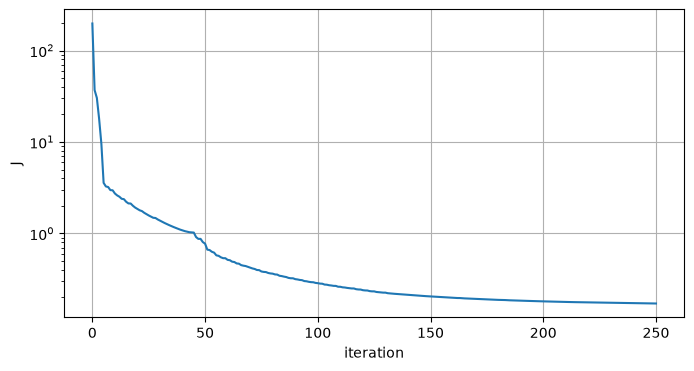

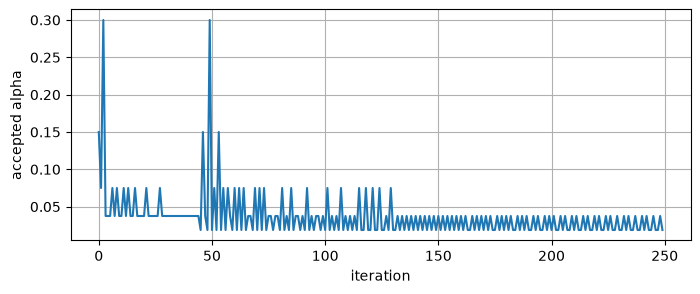

In [10]:
plt.figure(figsize=(8, 4))
plt.semilogy(history_bt)
plt.xlabel("iteration")
plt.ylabel("J")
plt.grid()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(alpha_bt)
plt.xlabel("iteration")
plt.ylabel("accepted alpha")
plt.grid()
plt.show()

Принятый шаг меняется по ходу оптимизации и подстраивается под текущую точку.

## 4. `L-BFGS-B` с заданным градиентом

На прошлом занятии `L-BFGS-B` уже появлялся как готовый solver. Теперь мы можем передать ему `jac` сами:

```python
minimize(..., jac=adjoint_gradient_pendulum)
```

Solver выбирает стратегию оптимизации, а производную получает из нашей модели ОУ.

In [11]:
bounds = [(-u_max, u_max)] * N

start = perf_counter()

res_with_jac = minimize(
    objective_pendulum,
    u0,
    jac=adjoint_gradient_pendulum,
    method="L-BFGS-B",
    bounds=bounds,
    options={
        "maxiter": 400,
        "ftol": 1e-10,
        "gtol": 1e-7,
    },
)

time_with_jac = perf_counter() - start

x_with_jac = simulate_pendulum(
    res_with_jac.x
)

print("success:", res_with_jac.success)
print("J =", res_with_jac.fun)
print("x(T) =", x_with_jac[-1])
print("iterations =", res_with_jac.nit)
print("nfev =", res_with_jac.nfev)
print("njev =", res_with_jac.njev)
print("time =", time_with_jac)

success: True
J = 0.1153075242295863
x(T) = [3.14002675 0.00518892]
iterations = 147
nfev = 194
njev = 194
time = 0.03949125000508502


### Сравнение с запуском без `jac`

Без `jac` метод оценивает градиент численно. Для управления из $N$ компонент это увеличивает число вычислений функционала.

Сравним на той же задаче.

In [12]:
start = perf_counter()

res_without_jac = minimize(
    objective_pendulum,
    u0,
    method="L-BFGS-B",
    bounds=bounds,
    options={
        "maxiter": 400,
        "maxfun": 30000,
        "ftol": 1e-10,
        "gtol": 1e-7,
    },
)

time_without_jac = perf_counter() - start

comparison = pd.DataFrame([
    {
        "variant": "L-BFGS-B + adjoint jac",
        "success": res_with_jac.success,
        "J": res_with_jac.fun,
        "nit": res_with_jac.nit,
        "nfev": res_with_jac.nfev,
        "njev": res_with_jac.njev,
        "time_s": time_with_jac,
    },
    {
        "variant": "L-BFGS-B without jac",
        "success": res_without_jac.success,
        "J": res_without_jac.fun,
        "nit": res_without_jac.nit,
        "nfev": res_without_jac.nfev,
        "njev": res_without_jac.njev,
        "time_s": time_without_jac,
    },
])

comparison

,variant,success,J,nit,nfev,njev,time_s
0,L-BFGS-B + adjoint jac,True,0.115308,147,194,194,0.039491
1,L-BFGS-B without jac,True,0.115308,145,14904,184,0.752453


Показатель `nfev` отражает число вычислений функционала и хорошо показывает цену численного градиента.

Время зависит от компьютера и фоновой нагрузки, поэтому его рассматриваем как дополнительный показатель.

### Наш алгоритм и `L-BFGS-B`

Оба метода используют один и тот же градиент. Разница в том, **как именно они выбирают следующий шаг**.

Наш projected gradient идёт прямо в сторону $-\nabla J$ и подбирает только длину шага. `L-BFGS-B` дополнительно накапливает информацию о том, как менялся градиент на предыдущих итерациях, и строит более удачное направление поиска.

Поэтому собственный projected gradient здесь нужен прежде всего как прозрачный алгоритм, в котором видно каждое действие. `L-BFGS-B` — уже рабочий численный метод.

In [13]:
methods = pd.DataFrame([
    {
        "method": "projected gradient + backtracking",
        "J": objective_pendulum(u_bt),
        "terminal_error": np.linalg.norm(x_bt[-1] - x_target),
        "max_abs_u": np.max(np.abs(u_bt)),
    },
    {
        "method": "L-BFGS-B + adjoint jac",
        "J": res_with_jac.fun,
        "terminal_error": np.linalg.norm(x_with_jac[-1] - x_target),
        "max_abs_u": np.max(np.abs(res_with_jac.x)),
    },
])

methods

,method,J,terminal_error,max_abs_u
0,projected gradient + backtracking,0.171635,0.042199,1.681115
1,L-BFGS-B + adjoint jac,0.115308,0.005420,1.120421


## 5. Оптимальное управление и траектория

Посмотрим на найденное управление и траекторию.

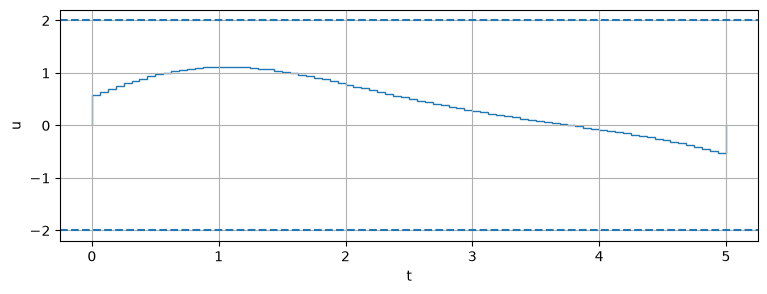

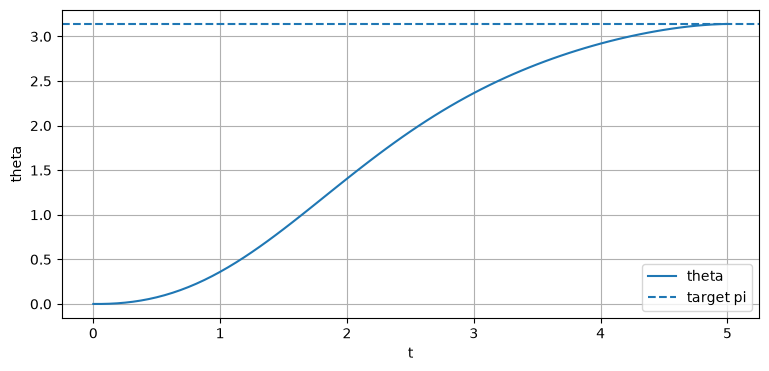

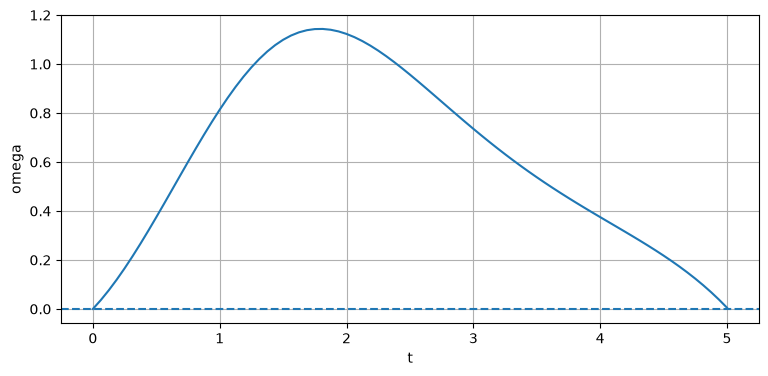

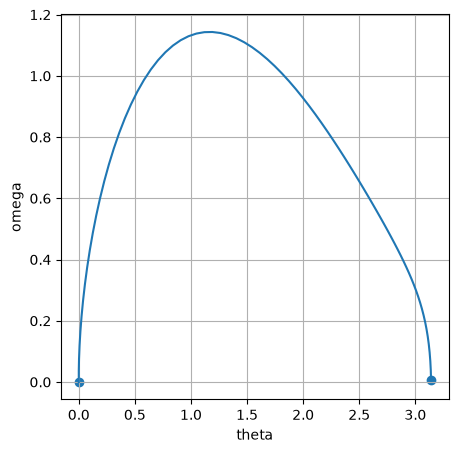

In [14]:
u_opt = res_with_jac.x
x_opt = simulate_pendulum(u_opt)

t = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 3))
plt.stairs(u_opt, t)
plt.axhline(u_max, linestyle="--")
plt.axhline(-u_max, linestyle="--")
plt.xlabel("t")
plt.ylabel("u")
plt.grid()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(t, x_opt[:, 0], label="theta")
plt.axhline(np.pi, linestyle="--", label="target pi")
plt.xlabel("t")
plt.ylabel("theta")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(t, x_opt[:, 1])
plt.axhline(0.0, linestyle="--")
plt.xlabel("t")
plt.ylabel("omega")
plt.grid()
plt.show()

plt.figure(figsize=(5, 5))
plt.plot(x_opt[:, 0], x_opt[:, 1])
plt.scatter(
    [x_opt[0, 0], x_opt[-1, 0]],
    [x_opt[0, 1], x_opt[-1, 1]],
)
plt.xlabel("theta")
plt.ylabel("omega")
plt.grid()
plt.show()

### Анимация движения

Теперь посмотрим на найденную траекторию как на движение маятника.

Положение груза:
$$
X(t)=\sin\theta(t),\qquad
Y(t)=-\cos\theta(t).
$$

Светлая точка наверху показывает целевое положение $\theta=\pi$. В подписи выводятся текущее время и управление.

In [15]:
def make_pendulum_animation(x, u, T, interval=70):
    n = len(u)
    t = np.linspace(0, T, n + 1)

    theta = x[:, 0]

    bob_x = np.sin(theta)
    bob_y = -np.cos(theta)

    fig, ax = plt.subplots(figsize=(5, 5))

    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

    ax.scatter(
        [0.0],
        [1.0],
        s=90,
        alpha=0.25,
        label="target",
    )

    rod, = ax.plot([], [], lw=3)
    bob, = ax.plot([], [], "o", ms=12)
    pivot, = ax.plot([0], [0], "o", ms=5)

    info = ax.text(
        0.03,
        0.95,
        "",
        transform=ax.transAxes,
        va="top",
    )

    ax.set_title("Optimal control of the pendulum")
    ax.legend(loc="lower right")

    def update(frame):
        x_bob = bob_x[frame]
        y_bob = bob_y[frame]

        rod.set_data(
            [0.0, x_bob],
            [0.0, y_bob],
        )
        bob.set_data([x_bob], [y_bob])

        if frame < n:
            u_now = u[frame]
        else:
            u_now = u[-1]

        info.set_text(
            f"t = {t[frame]:.2f}\\n"
            f"u = {u_now:.3f}\\n"
            f"theta = {theta[frame]:.3f}"
        )

        return rod, bob, pivot, info

    anim = FuncAnimation(
        fig,
        update,
        frames=n + 1,
        interval=interval,
        blit=True,
        repeat=True,
    )

    plt.close(fig)
    return anim


pendulum_animation = make_pendulum_animation(
    x_opt,
    u_opt,
    T,
)

HTML(pendulum_animation.to_jshtml())

### Вопросы по графикам

1. Используется ли ограничение $|u|\le2$ активно?
2. Почему управление может быть негладким?
3. Почему конечное состояние не совпадает с $(\pi,0)$ абсолютно точно?
4. Что изменится, если увеличить $\lambda$?

## 6. Зависит ли результат от начального управления?

Для нелинейной задачи результат может зависеть от начального приближения.

Проверим три старта:

- нулевое управление;
- синус;
- случайное небольшое управление.

Сначала сделайте прогноз: результаты будут одинаковыми или нет?

In [16]:
t_mid = (
    np.arange(N) + 0.5
) * T / N

rng = np.random.default_rng(1)

initial_guesses = {
    "zero": np.zeros(N),
    "sine": 0.8 * np.sin(
        2 * np.pi * t_mid / T
    ),
    "random": rng.uniform(
        -0.5,
        0.5,
        size=N,
    ),
}

rows = []
solutions = {}

for name, u_start in initial_guesses.items():
    res = minimize(
        objective_pendulum,
        u_start,
        jac=adjoint_gradient_pendulum,
        method="L-BFGS-B",
        bounds=bounds,
        options={
            "maxiter": 400,
            "ftol": 1e-10,
            "gtol": 1e-7,
        },
    )

    solutions[name] = res.x

    rows.append({
        "start": name,
        "success": res.success,
        "J": res.fun,
        "nit": res.nit,
        "nfev": res.nfev,
    })

pd.DataFrame(rows)

,start,success,J,nit,nfev
0,zero,True,0.115308,147,194
1,sine,True,0.115308,127,159
2,random,True,0.115308,160,206


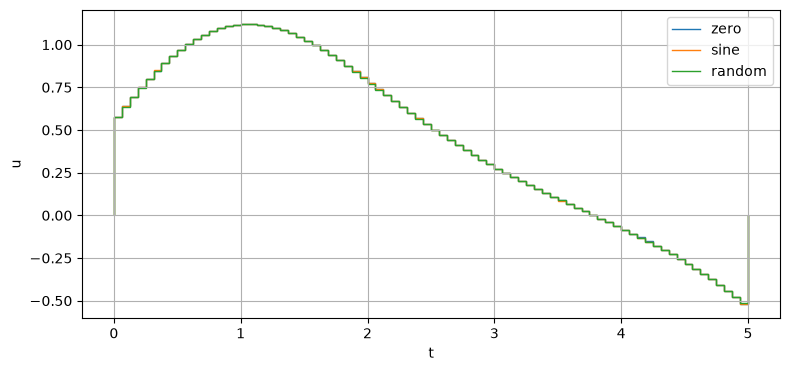

In [17]:
plt.figure(figsize=(9, 4))

for name, u in solutions.items():
    plt.stairs(
        u,
        np.linspace(0, T, N + 1),
        label=name,
    )

plt.xlabel("t")
plt.ylabel("u")
plt.grid()
plt.legend()
plt.show()

В этом конкретном эксперименте разные старты приводят практически к одному и тому же значению функционала. Это наблюдение для выбранных запусков; для других нелинейных задач результат может быть иным.

# Домашняя работа — срок 1 неделя

Домашняя работа продолжает расчёты этого notebook.

## 1. Сколько даёт собственный `jac`

Повторите сравнение `L-BFGS-B` с adjoint-gradient и без него для
$$
N=40,\quad80,\quad120.
$$

Для каждого запуска сохраните:

- `success`;
- $J$;
- `nit`;
- `nfev`;
- время.

Сделайте одну таблицу.

Постройте график `nfev` от $N$ для двух вариантов.

В нескольких предложениях объясните результат. В выводе отдельно отметьте, что отношение времён зависит от задачи и реализации.

,N,variant,success,J,nit,nfev,time_s
0,40,С jac,True,0.109625,139,177,0.018
1,40,Без jac,True,0.109625,176,9594,0.254
2,80,С jac,True,0.115308,147,194,0.035
3,80,Без jac,True,0.115308,145,14904,0.697
4,120,С jac,True,0.117215,163,209,0.058
5,120,Без jac,True,0.117215,184,29282,1.870


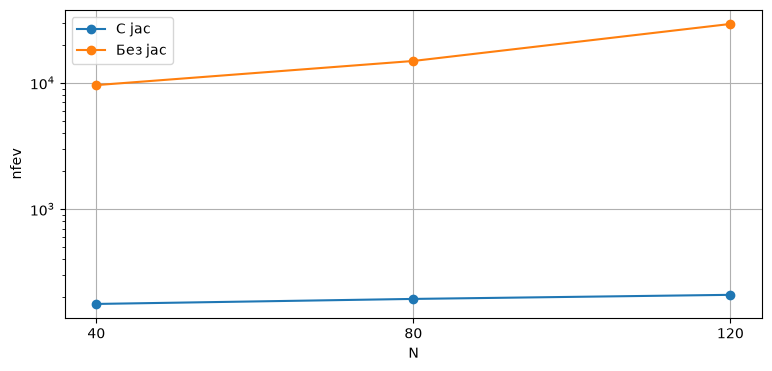

In [18]:
# Ваш код для задания 1
results = []

options = {
    "maxiter": 400,
    "maxfun": 30000,
    "ftol": 1e-10,
    "gtol": 1e-7,
}

for n in [40, 80, 120]:
    u_start = np.zeros(n)
    bounds_n = [(-u_max, u_max)] * n

    for variant, use_jac in [("С jac", True), ("Без jac", False)]:
        start = perf_counter()

        res = minimize(
            objective_pendulum,
            u_start,
            jac=adjoint_gradient_pendulum if use_jac else None,
            method="L-BFGS-B",
            bounds=bounds_n,
            options=options,
        )

        elapsed = perf_counter() - start

        results.append({
            "N": n,
            "variant": variant,
            "success": res.success,
            "J": res.fun,
            "nit": res.nit,
            "nfev": res.nfev,
            "time_s": elapsed,
        })

results_df = pd.DataFrame(results)
display(results_df.round({"J": 8, "time_s": 3}))

plt.figure(figsize=(9, 4))

for variant, group in results_df.groupby("variant", sort=False):
    plt.plot(
        group["N"],
        group["nfev"],
        marker="o",
        label=variant,
    )

plt.xlabel("N")
plt.ylabel("nfev")
plt.yscale("log")
plt.xticks([40, 80, 120])
plt.grid()
plt.legend()
plt.show()



<span style="color:red">Ответ:</span>

1. все запуски завершились успешно, при этом значения функционала для обоих вариантов совпадают с точностью до шести знаков после запятой

2. использование сопряжённого градиента сократило количество вычислений функционала примерно в 54, 77 и 140 раз при \(N = 40, 80, 120\) соответственно

3. при отсутствии `jac` градиент вычисляется численно, что требует дополнительных вычислений функционала для каждой компоненты управления, тогда как сопряжённый метод позволяет вычислить весь градиент за один прямой и один обратный проход

4. использование `jac` существенно сократило время вычислений для всех рассмотренных $N$, однако отношение времён зависит от конкретной задачи, её размерности, реализации алгоритмов и вычислительной среды


## 2. Что делает штраф на управление

Решите задачу с adjoint-gradient для
$$
\lambda=0.01,\quad0.05,\quad0.20.
$$

Для каждого решения вычислите:

- terminal error
$$
\|x(T)-x_{\rm target}\|;
$$
- control effort
$$
h\sum_k u_k^2;
$$
- $\max_k|u_k|$;
- значение $J$.

Постройте три управления $u(t)$ на одном графике.

Объясните, какой компромисс задаёт параметр $\lambda$.

,lambda,success,terminal_error,control_effort,max_abs_u,J
0,0.01,True,0.001101,2.308393,1.123926,0.023092
1,0.05,True,0.005420,2.302477,1.120421,0.115308
2,0.20,True,0.020366,2.282750,1.117001,0.459155


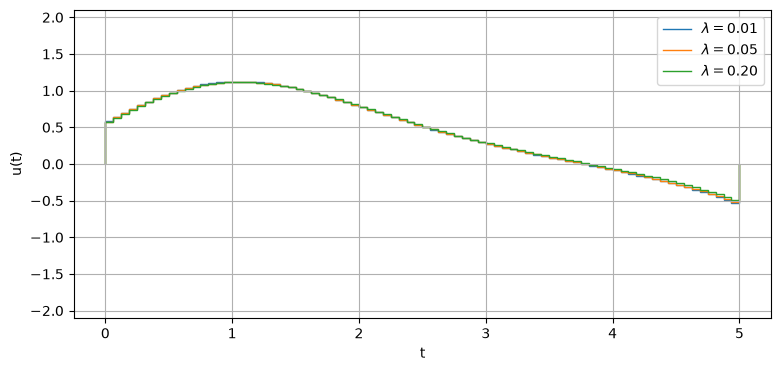

In [19]:

lambda_values = [0.01, 0.05, 0.20]
n_lambda = 80
h = T / n_lambda
bounds_lambda = [(-u_max, u_max)] * n_lambda

lambda_results = {}
rows = []

for lam_value in lambda_values:
    res = minimize(
        objective_pendulum,
        np.zeros(n_lambda),
        args=(lam_value,),
        jac=adjoint_gradient_pendulum,
        method="L-BFGS-B",
        bounds=bounds_lambda,
        options={
            "maxiter": 400,
            "ftol": 1e-10,
            "gtol": 1e-7,
        },
    )

    u = res.x
    x = simulate_pendulum(u)

    lambda_results[lam_value] = u

    rows.append({
        "lambda": lam_value,
        "success": res.success,
        "terminal_error": np.linalg.norm(x[-1] - x_target),
        "control_effort": h * np.sum(u**2),
        "max_abs_u": np.max(np.abs(u)),
        "J": res.fun,
    })

lambda_df = pd.DataFrame(rows)
display(lambda_df.round(6))

t_edges = np.linspace(0, T, n_lambda + 1)

plt.figure(figsize=(9, 4))

for lam_value, u in lambda_results.items():
    plt.stairs(
        u,
        t_edges,
        label=rf"$\lambda = {lam_value:.2f}$",
    )

plt.xlabel("t")
plt.ylabel("u(t)")
plt.ylim(-u_max - 0.1, u_max + 0.1)
plt.grid()
plt.legend()
plt.show()



<span style="color:red">Ответ:</span>

1. все три запуска завершились успешно, при увеличении $\lambda$ от $0.01$ до $0.20$ терминальная ошибка возрастает с $0.001101$ до $0.020366$

2. затраты на управление уменьшаются с $2.308393$ до $2.282750$, а максимальное абсолютное значение управления — с $1.123926$ до $1.117001$

3. на графике три управления практически совпадают, однако при увеличении $\lambda$ наблюдаются небольшие изменения их формы и амплитуды

4. параметр $\lambda$ задаёт компромисс между точностью достижения целевого состояния и затратами на управление: увеличение $\lambda$ усиливает штраф за управление, снижая его затраты ценой увеличения терминальной ошибки


## 3. Начальное приближение

Для $N=80$ придумайте ещё **два** начальных управления помимо трёх, которые были на занятии.

Например, можно взять:

- постоянное управление;
- кусочно-постоянное «разгон–торможение»;
- синус с другой частотой.

Запустите `L-BFGS-B` с нашим `jac`.

Сравните $J$, число итераций и найденные управления.

Если все старты приводят практически к одному решению, зафиксируйте это как результат эксперимента.

,start,success,J,nit,nfev,max_diff_from_zero
0,zero,True,0.115308,147,194,0.000000
1,sine,True,0.115308,127,159,0.000837
2,random,True,0.115308,160,206,0.002658
3,constant,True,0.115308,89,113,0.000458
4,accel_brake,True,0.115308,69,80,0.001683


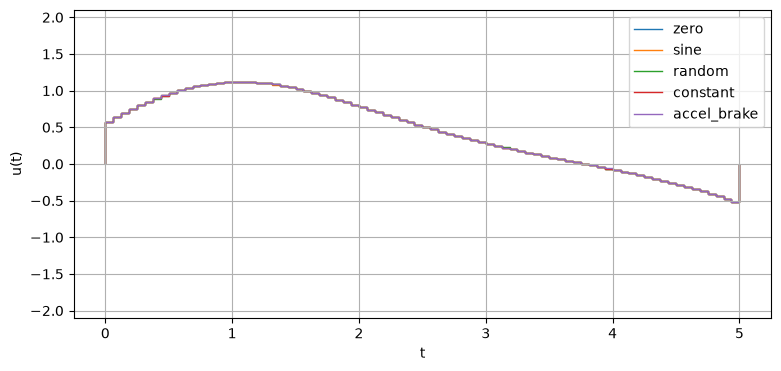

In [20]:
# Ваш код для задания 3
initial_guesses_hw = {
    **initial_guesses,
    "constant": np.full(N, 0.5),
    "accel_brake": np.where(np.arange(N) < N // 2, 1.0, -1.0),
}

solutions_hw = {}
rows_hw = []

for name, u_start in initial_guesses_hw.items():
    res = minimize(
        objective_pendulum,
        u_start,
        jac=adjoint_gradient_pendulum,
        method="L-BFGS-B",
        bounds=[(-u_max, u_max)] * N,
        options={
            "maxiter": 400,
            "ftol": 1e-10,
            "gtol": 1e-7,
        },
    )

    solutions_hw[name] = res.x

    rows_hw.append({
        "start": name,
        "success": res.success,
        "J": res.fun,
        "nit": res.nit,
        "nfev": res.nfev,
    })

comparison_hw = pd.DataFrame(rows_hw)

comparison_hw["max_diff_from_zero"] = [
    np.max(np.abs(solutions_hw[name] - solutions_hw["zero"]))
    for name in comparison_hw["start"]
]

display(comparison_hw.round({
    "J": 9,
    "max_diff_from_zero": 6,
}))

plt.figure(figsize=(9, 4))

for name, u in solutions_hw.items():
    plt.stairs(
        u,
        np.linspace(0, T, N + 1),
        label=name,
    )

plt.xlabel("t")
plt.ylabel("u(t)")
plt.ylim(-u_max - 0.1, u_max + 0.1)
plt.grid()
plt.legend()
plt.show()


<span style="color:red">Ответ:</span>

1. все пять запусков завершились успешно и привели практически к одному значению функционала $J \approx 0.115308$

2. найденные управления практически совпадают, максимальное отклонение от решения с нулевым начальным приближением не превышает $0.002658$, что также подтверждается графиком

3. число итераций зависит от начального приближения: минимальное количество ($69$) получено для `accel_brake`, максимальное ($160$) — для `random`

4. в данном эксперименте выбор начального приближения существенно влияет на скорость сходимости, но практически не влияет на найденное решение, при этом совпадение результатов не гарантирует нахождения глобального минимума


## Итог

В конце оставьте короткий вывод:

- зачем нужен line search;
- что даёт solver'у adjoint-gradient;
- чем отличаются роли `objective`, `jac` и самого алгоритма `L-BFGS-B`;
- что показал эксперимент с $\lambda$;
- повлияло ли начальное приближение в ваших запусках.

Перед сдачей: `Restart Kernel → Run All`.


<span style="color:red">Ответ:</span>

1. `line search` позволяет автоматически подбирать шаг оптимизации, обеспечивая достаточное уменьшение функционала и предотвращая неустойчивое поведение при слишком большом шаге

2. сопряжённый градиент позволяет вычислять производные функционала без численного дифференцирования по каждой компоненте управления, что существенно сокращает число вычислений функционала и время работы оптимизатора

3. `objective` вычисляет значение минимизируемого функционала, `jac` — его градиент по управлению, а `L-BFGS-B` использует эти данные для поиска минимума с учётом ограничений на управление

4. увеличение $\lambda$ от $0.01$ до $0.20$ уменьшило затраты на управление с $2.308393$ до $2.282750$, но увеличило терминальную ошибку с $0.001101$ до $0.020366$, что демонстрирует компромисс между точностью достижения цели и затратами на управление

5. в проведённых экспериментах все пять начальных приближений привели практически к одному решению с $J \approx 0.115308$, однако число итераций изменялось от $69$ до $160$, следовательно, начальное приближение повлияло на скорость сходимости, но практически не повлияло на полученное решение
